In [1]:
!nvidia-smi

Tue Nov 17 15:27:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is NOT available")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
!pip install -q datasets

from datasets import load_dataset

# Stream the dataset without downloading all 112,120 images to disk
dataset = load_dataset("BahaaEldin0/NIH-Chest-Xray-14", split="train", streaming=True)

# Inspect the first record to verify columns and labels
sample = next(iter(dataset))
print("Available keys:", list(sample.keys()))
print("Sample metadata:", {k: v for k, v in sample.items() if k != "image"})

README.md:   0%|          | 0.00/710 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/73 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/73 [00:00<?, ?it/s]

Available keys: ['image', 'label', 'Patient Age', 'Patient Gender', 'View Position', 'Patient ID']
Sample metadata: {'label': ['No Finding'], 'Patient Age': 71, 'Patient Gender': 'M', 'View Position': 'PA', 'Patient ID': 7943}


In [6]:
import os
import pandas as pd
from collections import defaultdict
from tqdm.auto import tqdm
from datasets import load_dataset

# Re-open the stream cleanly from the start
dataset = load_dataset("BahaaEldin0/NIH-Chest-Xray-14", split="train", streaming=True)

# Inspect first row to automatically detect exact keys
first_row = next(iter(dataset))
print("Detected keys:", list(first_row.keys()))
for k, v in first_row.items():
    if k != "image":
        print(f"  {k}: {v} (type: {type(v).__name__})")

SAVE_DIR = "/content/nih_subset/images"
os.makedirs(SAVE_DIR, exist_ok=True)

TARGET_PER_CLASS = 250
MAX_NO_FINDING = 500
MAX_SCAN_LIMIT = 25000

PATHOLOGIES = [
    "Atelectasis", "Cardiomegaly", "Consolidation", "Edema",
    "Effusion", "Emphysema", "Fibrosis", "Hernia",
    "Infiltration", "Mass", "Nodule", "Pleural_Thickening",
    "Pneumonia", "Pneumothorax"
]

# Detect label column name and class list dynamically
label_col = next((k for k in first_row.keys() if "label" in k.lower() or "finding" in k.lower()), None)
patient_col = next((k for k in first_row.keys() if "patient" in k.lower()), None)

feat = dataset.features.get(label_col)
label_names = feat.feature.names if hasattr(feat, "feature") and hasattr(feat.feature, "names") else None

class_counts = defaultdict(int)
records = []

# Re-open stream so row 0 isn't skipped
dataset = load_dataset("BahaaEldin0/NIH-Chest-Xray-14", split="train", streaming=True)

for idx, row in enumerate(tqdm(dataset, total=MAX_SCAN_LIMIT, desc="Sampling stream")):
    if idx >= MAX_SCAN_LIMIT:
        break

    raw_val = row[label_col]
    if isinstance(raw_val, str):
        labels = [x.strip() for x in raw_val.split("|")]
    elif isinstance(raw_val, list):
        labels = [label_names[i] if (isinstance(i, int) and label_names) else str(i) for i in raw_val]
    else:
        continue

    keep = False
    if labels == ["No Finding"] or len(labels) == 0:
        labels = ["No Finding"]
        if class_counts["No Finding"] < MAX_NO_FINDING:
            keep = True
    else:
        for lbl in labels:
            if lbl in PATHOLOGIES and class_counts[lbl] < TARGET_PER_CLASS:
                keep = True
                break

    if keep:
        img_filename = f"xray_{len(records):05d}.png"
        img_path = os.path.join(SAVE_DIR, img_filename)
        row["image"].convert("RGB").resize((224, 224)).save(img_path)

        patient_id = row[patient_col] if patient_col else f"P_{len(records)}"
        records.append({
            "image_path": img_path,
            "patient_id": patient_id,
            "raw_labels": "|".join(labels)
        })

        for lbl in labels:
            class_counts[lbl] += 1

    if (class_counts["No Finding"] >= MAX_NO_FINDING and
        all(class_counts[p] >= TARGET_PER_CLASS for p in PATHOLOGIES)):
        print("All class quotas filled early!")
        break

assert len(records) > 0, f"Still 0 records saved! Sample label value was: {first_row[label_col]}"

df_subset = pd.DataFrame(records)
df_subset.to_csv("/content/nih_subset/metadata.csv", index=False)

print(f"\nSaved {len(df_subset)} images to {SAVE_DIR}")
print("\nClass distribution in subset:")
for k in ["No Finding"] + PATHOLOGIES:
    print(f"  {k:<20}: {class_counts[k]}")

Resolving data files:   0%|          | 0/73 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/73 [00:00<?, ?it/s]

Detected keys: ['image', 'label', 'Patient Age', 'Patient Gender', 'View Position', 'Patient ID']
  label: ['No Finding'] (type: list)
  Patient Age: 71 (type: int)
  Patient Gender: M (type: str)
  View Position: PA (type: str)
  Patient ID: 7943 (type: int)


Resolving data files:   0%|          | 0/73 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/73 [00:00<?, ?it/s]

Sampling stream:   0%|          | 0/25000 [00:00<?, ?it/s]


Saved 3065 images to /content/nih_subset/images

Class distribution in subset:
  No Finding          : 500
  Atelectasis         : 484
  Cardiomegaly        : 263
  Consolidation       : 285
  Edema               : 275
  Effusion            : 576
  Emphysema           : 256
  Fibrosis            : 250
  Hernia              : 67
  Infiltration        : 741
  Mass                : 327
  Nodule              : 313
  Pleural_Thickening  : 275
  Pneumonia           : 250
  Pneumothorax        : 323


In [7]:
import numpy as np
import pandas as pd

# Load the saved subset metadata
df = pd.read_csv("/content/nih_subset/metadata.csv")

# Fixed alphabetical ordering of the 14 NIH ChestX-ray14 pathologies
PATHOLOGIES = [
    "Atelectasis", "Cardiomegaly", "Consolidation", "Edema",
    "Effusion", "Emphysema", "Fibrosis", "Hernia",
    "Infiltration", "Mass", "Nodule", "Pleural_Thickening",
    "Pneumonia", "Pneumothorax"
]

# Create one binary column (0 or 1) per pathology
for pathology in PATHOLOGIES:
    df[pathology] = df["raw_labels"].apply(
        lambda x: 1.0 if pathology in str(x).split("|") else 0.0
    )

# Store the 14-dimensional vector as a list column for quick inspection
df["target_vector"] = df[PATHOLOGIES].values.tolist()

# Save updated metadata
df.to_csv("/content/nih_subset/metadata_encoded.csv", index=False)

print("Encoded DataFrame shape:", df.shape)
print("\nSample multi-hot encodings:")
for i in range(min(5, len(df))):
    row = df.iloc[i]
    vec = [int(v) for v in row["target_vector"]]
    print(f"  Row {i} | Labels: {row['raw_labels']:<30} -> {vec}")

# Check co-occurrence stats (how many images have 0, 1, or multiple simultaneous diseases)
label_sums = df[PATHOLOGIES].sum(axis=1)
print("\nPathologies per image breakdown:")
print(label_sums.value_counts().sort_index().rename("image_count"))

Encoded DataFrame shape: (3065, 18)

Sample multi-hot encodings:
  Row 0 | Labels: No Finding                     -> [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  Row 1 | Labels: No Finding                     -> [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  Row 2 | Labels: No Finding                     -> [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  Row 3 | Labels: No Finding                     -> [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  Row 4 | Labels: Nodule                         -> [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0]

Pathologies per image breakdown:
0.0     500
1.0    1188
2.0     830
3.0     399
4.0     110
5.0      30
6.0       7
8.0       1
Name: image_count, dtype: int64


In [8]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

df = pd.read_csv("/content/nih_subset/metadata_encoded.csv")

PATHOLOGIES = [
    "Atelectasis", "Cardiomegaly", "Consolidation", "Edema",
    "Effusion", "Emphysema", "Fibrosis", "Hernia",
    "Infiltration", "Mass", "Nodule", "Pleural_Thickening",
    "Pneumonia", "Pneumothorax"
]

# Step 1: Split 70% Train and 30% Temp (Validation + Test) grouped by patient_id
gss_train = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss_train.split(df, groups=df["patient_id"]))

train_df = df.iloc[train_idx].reset_index(drop=True)
temp_df = df.iloc[temp_idx].reset_index(drop=True)

# Step 2: Split the 30% Temp equally into 15% Validation and 15% Test grouped by patient_id
gss_val_test = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss_val_test.split(temp_df, groups=temp_df["patient_id"]))

val_df = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

# Verify zero patient leakage across all three splits
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

assert len(train_patients & val_patients) == 0, "Leakage between Train and Val!"
assert len(train_patients & test_patients) == 0, "Leakage between Train and Test!"
assert len(val_patients & test_patients) == 0, "Leakage between Val and Test!"

# Save the three split CSVs
train_df.to_csv("/content/nih_subset/train.csv", index=False)
val_df.to_csv("/content/nih_subset/val.csv", index=False)
test_df.to_csv("/content/nih_subset/test.csv", index=False)

print(f"Train : {len(train_df):4d} images | {len(train_patients):4d} unique patients")
print(f"Val   : {len(val_df):4d} images | {len(val_patients):4d} unique patients")
print(f"Test  : {len(test_df):4d} images | {len(test_patients):4d} unique patients")
print("\nZero patient overlap verified across all splits!")

# Check class distribution across splits
split_summary = pd.DataFrame({
    "Train": train_df[PATHOLOGIES].sum().astype(int),
    "Val": val_df[PATHOLOGIES].sum().astype(int),
    "Test": test_df[PATHOLOGIES].sum().astype(int)
})
print("\nPathology counts per split:")
print(split_summary)

Train : 2177 images |   64 unique patients
Val   :  454 images |   14 unique patients
Test  :  434 images |   14 unique patients

Zero patient overlap verified across all splits!

Pathology counts per split:
                    Train  Val  Test
Atelectasis           356   53    75
Cardiomegaly          189   37    37
Consolidation         212   31    42
Edema                 196   38    41
Effusion              406   77    93
Emphysema             170   50    36
Fibrosis              188   36    26
Hernia                 52   11     4
Infiltration          523  113   105
Mass                  241   41    45
Nodule                234   36    43
Pleural_Thickening    200   43    32
Pneumonia             178   42    30
Pneumothorax          208   65    50


In [9]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import pandas as pd

PATHOLOGIES = [
    "Atelectasis", "Cardiomegaly", "Consolidation", "Edema",
    "Effusion", "Emphysema", "Fibrosis", "Hernia",
    "Infiltration", "Mass", "Nodule", "Pleural_Thickening",
    "Pneumonia", "Pneumothorax"
]

# ImageNet normalization stats expected by pretrained DenseNet121
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Training transforms: gentle clinically plausible augmentations
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Validation & Test transforms: deterministic normalization only
eval_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

class ChestXRayDataset(Dataset):
    def __init__(self, csv_path, transform=None):
        self.df = pd.read_csv(csv_path)
        self.transform = transform
        self.image_paths = self.df["image_path"].values
        self.labels = self.df[PATHOLOGIES].values.astype("float32")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        target = torch.tensor(self.labels[idx], dtype=torch.float32)
        return img, target

# Instantiate datasets
train_dataset = ChestXRayDataset("/content/nih_subset/train.csv", transform=train_transforms)
val_dataset   = ChestXRayDataset("/content/nih_subset/val.csv",   transform=eval_transforms)
test_dataset  = ChestXRayDataset("/content/nih_subset/test.csv",  transform=eval_transforms)

# Instantiate DataLoaders
BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# Sanity check one batch
sample_imgs, sample_targets = next(iter(train_loader))
print("Batch image tensor shape :", sample_imgs.shape)   # Expected: [32, 3, 224, 224]
print("Batch target tensor shape:", sample_targets.shape) # Expected: [32, 14]
print("Pixel value range        :", f"[{sample_imgs.min():.2f}, {sample_imgs.max():.2f}]")

Batch image tensor shape : torch.Size([32, 3, 224, 224])
Batch target tensor shape: torch.Size([32, 14])
Pixel value range        : [-2.12, 2.64]


In [10]:
import torch
import torch.nn as nn
from torchvision import models
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load ImageNet-pretrained DenseNet121
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

# 2. Replace the 1000-class ImageNet head with a 14-pathology linear classifier
num_features = model.classifier.in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.2),
    nn.Linear(num_features, 14)
)
model = model.to(device)

# 3. Compute class-imbalance pos_weight from training set ONLY (zero leakage)
train_df = pd.read_csv("/content/nih_subset/train.csv")
pos_counts = torch.tensor(train_df[PATHOLOGIES].sum().values, dtype=torch.float32)
neg_counts = len(train_df) - pos_counts

# pos_weight = (# negative samples) / (# positive samples) for each pathology
pos_weight = (neg_counts / pos_counts.clamp(min=1)).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# 4. AdamW optimizer + ReduceLROnPlateau scheduler
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

total_params = sum(p.numel() for p in model.parameters())
print(f"DenseNet121 ready on {device} | Total parameters: {total_params:,}")
print("\nComputed pos_weight per pathology (higher = rarer disease):")
for name, w in zip(PATHOLOGIES, pos_weight.cpu().numpy()):
    print(f"  {name:<20}: {w:.2f}")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 109MB/s] 


DenseNet121 ready on cuda | Total parameters: 6,968,206

Computed pos_weight per pathology (higher = rarer disease):
  Atelectasis         : 5.12
  Cardiomegaly        : 10.52
  Consolidation       : 9.27
  Edema               : 10.11
  Effusion            : 4.36
  Emphysema           : 11.81
  Fibrosis            : 10.58
  Hernia              : 40.87
  Infiltration        : 3.16
  Mass                : 8.03
  Nodule              : 8.30
  Pleural_Thickening  : 9.89
  Pneumonia           : 11.23
  Pneumothorax        : 9.47


In [11]:
import numpy as np
import torch
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

EPOCHS = 10
BEST_MODEL_PATH = "/content/nih_subset/best_densenet121.pth"

scaler = torch.amp.GradScaler("cuda")
history = {"train_loss": [], "val_loss": [], "val_mean_auc": []}
best_val_auc = 0.0

for epoch in range(1, EPOCHS + 1):
    # --- TRAINING PHASE ---
    model.train()
    running_train_loss = 0.0

    for imgs, targets in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=False):
        imgs, targets = imgs.to(device), targets.to(device)
        optimizer.zero_grad()

        with torch.amp.autocast("cuda"):
            logits = model(imgs)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_train_loss += loss.item() * imgs.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset)

    # --- VALIDATION PHASE ---
    model.eval()
    running_val_loss = 0.0
    all_val_probs = []
    all_val_targets = []

    with torch.no_grad():
        for imgs, targets in val_loader:
            imgs, targets = imgs.to(device), targets.to(device)
            with torch.amp.autocast("cuda"):
                logits = model(imgs)
                loss = criterion(logits, targets)

            running_val_loss += loss.item() * imgs.size(0)
            probs = torch.sigmoid(logits).cpu().numpy()
            all_val_probs.append(probs)
            all_val_targets.append(targets.cpu().numpy())

    epoch_val_loss = running_val_loss / len(val_dataset)
    val_probs = np.vstack(all_val_probs)
    val_targets = np.vstack(all_val_targets)

    # Compute macro ROC-AUC across pathologies that have at least one positive & negative case
    class_aucs = []
    for i in range(14):
        if len(np.unique(val_targets[:, i])) > 1:
            class_aucs.append(roc_auc_score(val_targets[:, i], val_probs[:, i]))
    mean_val_auc = float(np.mean(class_aucs))

    # Step LR scheduler using validation AUC
    scheduler.step(mean_val_auc)

    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["val_mean_auc"].append(mean_val_auc)

    saved_flag = ""
    if mean_val_auc > best_val_auc:
        best_val_auc = mean_val_auc
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        saved_flag = "  <-- Saved Best Model"

    print(
        f"Epoch {epoch:02d}/{EPOCHS:02d} | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Mean AUC: {mean_val_auc:.4f}{saved_flag}"
    )

print(f"\nTraining complete! Best Validation Mean AUC: {best_val_auc:.4f}")

Epoch 1/10 [Train]:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 1.2131 | Val Loss: 1.1529 | Val Mean AUC: 0.6584  <-- Saved Best Model


Epoch 2/10 [Train]:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 1.0965 | Val Loss: 1.1027 | Val Mean AUC: 0.6928  <-- Saved Best Model


Epoch 3/10 [Train]:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 03/10 | Train Loss: 1.0290 | Val Loss: 1.0766 | Val Mean AUC: 0.7100  <-- Saved Best Model


... (12 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f4b508e0900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f4b508e0900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 09/10 | Train Loss: 0.6601 | Val Loss: 1.1337 | Val Mean AUC: 0.7361


Epoch 10/10 [Train]:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.6130 | Val Loss: 1.1547 | Val Mean AUC: 0.7357

Training complete! Best Validation Mean AUC: 0.7416


In [12]:
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score, f1_score, recall_score, precision_score, roc_curve

# 1. Load the best saved checkpoint
model.load_state_dict(torch.load("/content/nih_subset/best_densenet121.pth", map_location=device))
model.eval()

def get_predictions(loader):
    probs_list, targets_list = [], []
    with torch.no_grad():
        for imgs, targets in loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            probs = torch.sigmoid(logits).cpu().numpy()
            probs_list.append(probs)
            targets_list.append(targets.numpy())
    return np.vstack(probs_list), np.vstack(targets_list)

val_probs, val_targets   = get_predictions(val_loader)
test_probs, test_targets = get_predictions(test_loader)

# 2. Find optimal per-class probability thresholds on VALIDATION set (Youden's J = TPR - FPR)
optimal_thresholds = []
for i in range(14):
    if len(np.unique(val_targets[:, i])) > 1:
        fpr, tpr, thresholds = roc_curve(val_targets[:, i], val_probs[:, i])
        best_idx = np.argmax(tpr - fpr)
        optimal_thresholds.append(float(thresholds[best_idx]))
    else:
        optimal_thresholds.append(0.5)

# 3. Evaluate on TEST set using the validation-derived thresholds
results = []
for i, pathology in enumerate(PATHOLOGIES):
    y_true = test_targets[:, i]
    y_prob = test_probs[:, i]
    thresh = optimal_thresholds[i]
    y_pred = (y_prob >= thresh).astype(int)

    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else np.nan
    f1  = f1_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    pre = precision_score(y_true, y_pred, zero_division=0)

    results.append({
        "Pathology": pathology,
        "Test_Positives": int(y_true.sum()),
        "Threshold": round(thresh, 3),
        "AUC": round(auc, 4),
        "F1": round(f1, 4),
        "Recall": round(rec, 4),
        "Precision": round(pre, 4)
    })

results_df = pd.DataFrame(results)
results_df.to_csv("/content/nih_subset/test_metrics.csv", index=False)

print("=== HELD-OUT TEST SET PERFORMANCE (PATIENT-ISOLATED) ===")
print(results_df.to_string(index=False))
print("\n--- Macro Averages Across 14 Pathologies ---")
print(f"Mean Test AUC      : {results_df['AUC'].mean():.4f}")
print(f"Mean Test F1-Score : {results_df['F1'].mean():.4f}")
print(f"Mean Test Recall   : {results_df['Recall'].mean():.4f}")

=== HELD-OUT TEST SET PERFORMANCE (PATIENT-ISOLATED) ===
         Pathology  Test_Positives  Threshold    AUC     F1  Recall  Precision
       Atelectasis              75      0.492 0.6635 0.3704  0.5333     0.2837
      Cardiomegaly              37      0.445 0.8293 0.3195  0.7297     0.2045
     Consolidation              42      0.450 0.6529 0.2600  0.6190     0.1646
             Edema              41      0.316 0.8615 0.3333  0.8537     0.2071
          Effusion              93      0.499 0.7924 0.5425  0.7204     0.4351
         Emphysema              36      0.394 0.8165 0.3373  0.7778     0.2154
          Fibrosis              26      0.424 0.7038 0.1854  0.5385     0.1120
            Hernia               4      0.201 0.9512 0.0727  1.0000     0.0377
      Infiltration             105      0.381 0.6835 0.4606  0.6952     0.3443
              Mass              45      0.410 0.6473 0.2281  0.8667     0.1313
            Nodule              43      0.384 0.6844 0.2273  0.8140     0.

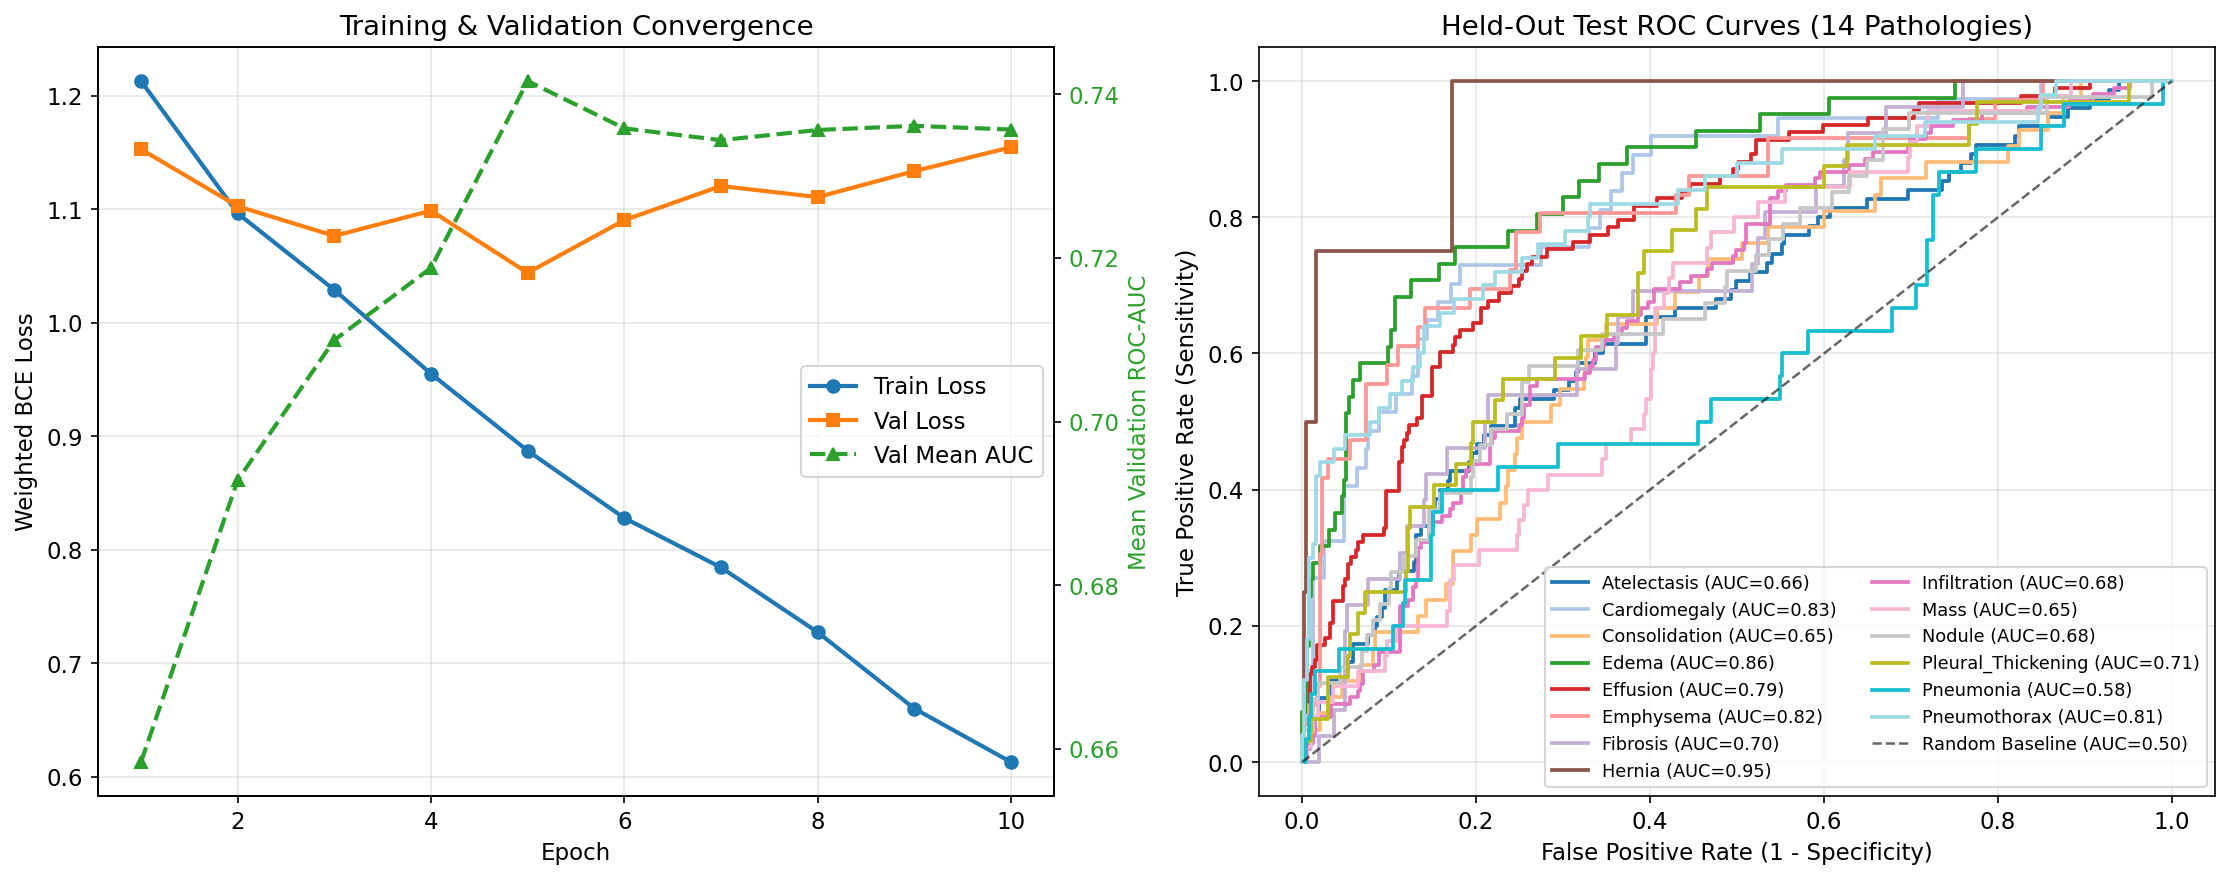

Saved high-resolution figure to /content/nih_subset/roc_and_training_curves.png


In [14]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

# Set clean academic plot styling
plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.alpha": 0.3})

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# --- PANEL A: Training vs Validation Loss & Mean Val AUC ---
epochs_range = range(1, len(history["train_loss"]) + 1)

ax1 = axes[0]
l1 = ax1.plot(epochs_range, history["train_loss"], "o-", color="#1f77b4", lw=2, label="Train Loss")
l2 = ax1.plot(epochs_range, history["val_loss"],   "s-", color="#ff7f0e", lw=2, label="Val Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Weighted BCE Loss")
ax1.set_title("Training & Validation Convergence")

ax1_twin = ax1.twinx()
ax1_twin.grid(False)
l3 = ax1_twin.plot(epochs_range, history["val_mean_auc"], "^--", color="#2ca02c", lw=2, label="Val Mean AUC")
ax1_twin.set_ylabel("Mean Validation ROC-AUC", color="#2ca02c")
ax1_twin.tick_params(axis="y", labelcolor="#2ca02c")

# Combine legends from both y-axes
lines = l1 + l2 + l3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="center right")

# --- PANEL B: Multi-Label ROC Curves Across All 14 Pathologies ---
ax2 = axes[1]
colors = plt.cm.tab20(np.linspace(0, 1, 14))

for i, pathology in enumerate(PATHOLOGIES):
    y_true = test_targets[:, i]
    y_prob = test_probs[:, i]
    if len(np.unique(y_true)) > 1:
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        auc_val = roc_auc_score(y_true, y_prob)
        ax2.plot(fpr, tpr, lw=1.8, color=colors[i], label=f"{pathology} (AUC={auc_val:.2f})")

ax2.plot([0, 1], [0, 1], "k--", lw=1.2, alpha=0.6, label="Random Baseline (AUC=0.50)")
ax2.set_xlabel("False Positive Rate (1 - Specificity)")
ax2.set_ylabel("True Positive Rate (Sensitivity)")
ax2.set_title("Held-Out Test ROC Curves (14 Pathologies)")
ax2.legend(loc="lower right", fontsize=8.5, ncol=2)

plt.tight_layout()
plt.savefig("/content/nih_subset/roc_and_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved high-resolution figure to /content/nih_subset/roc_and_training_curves.png")

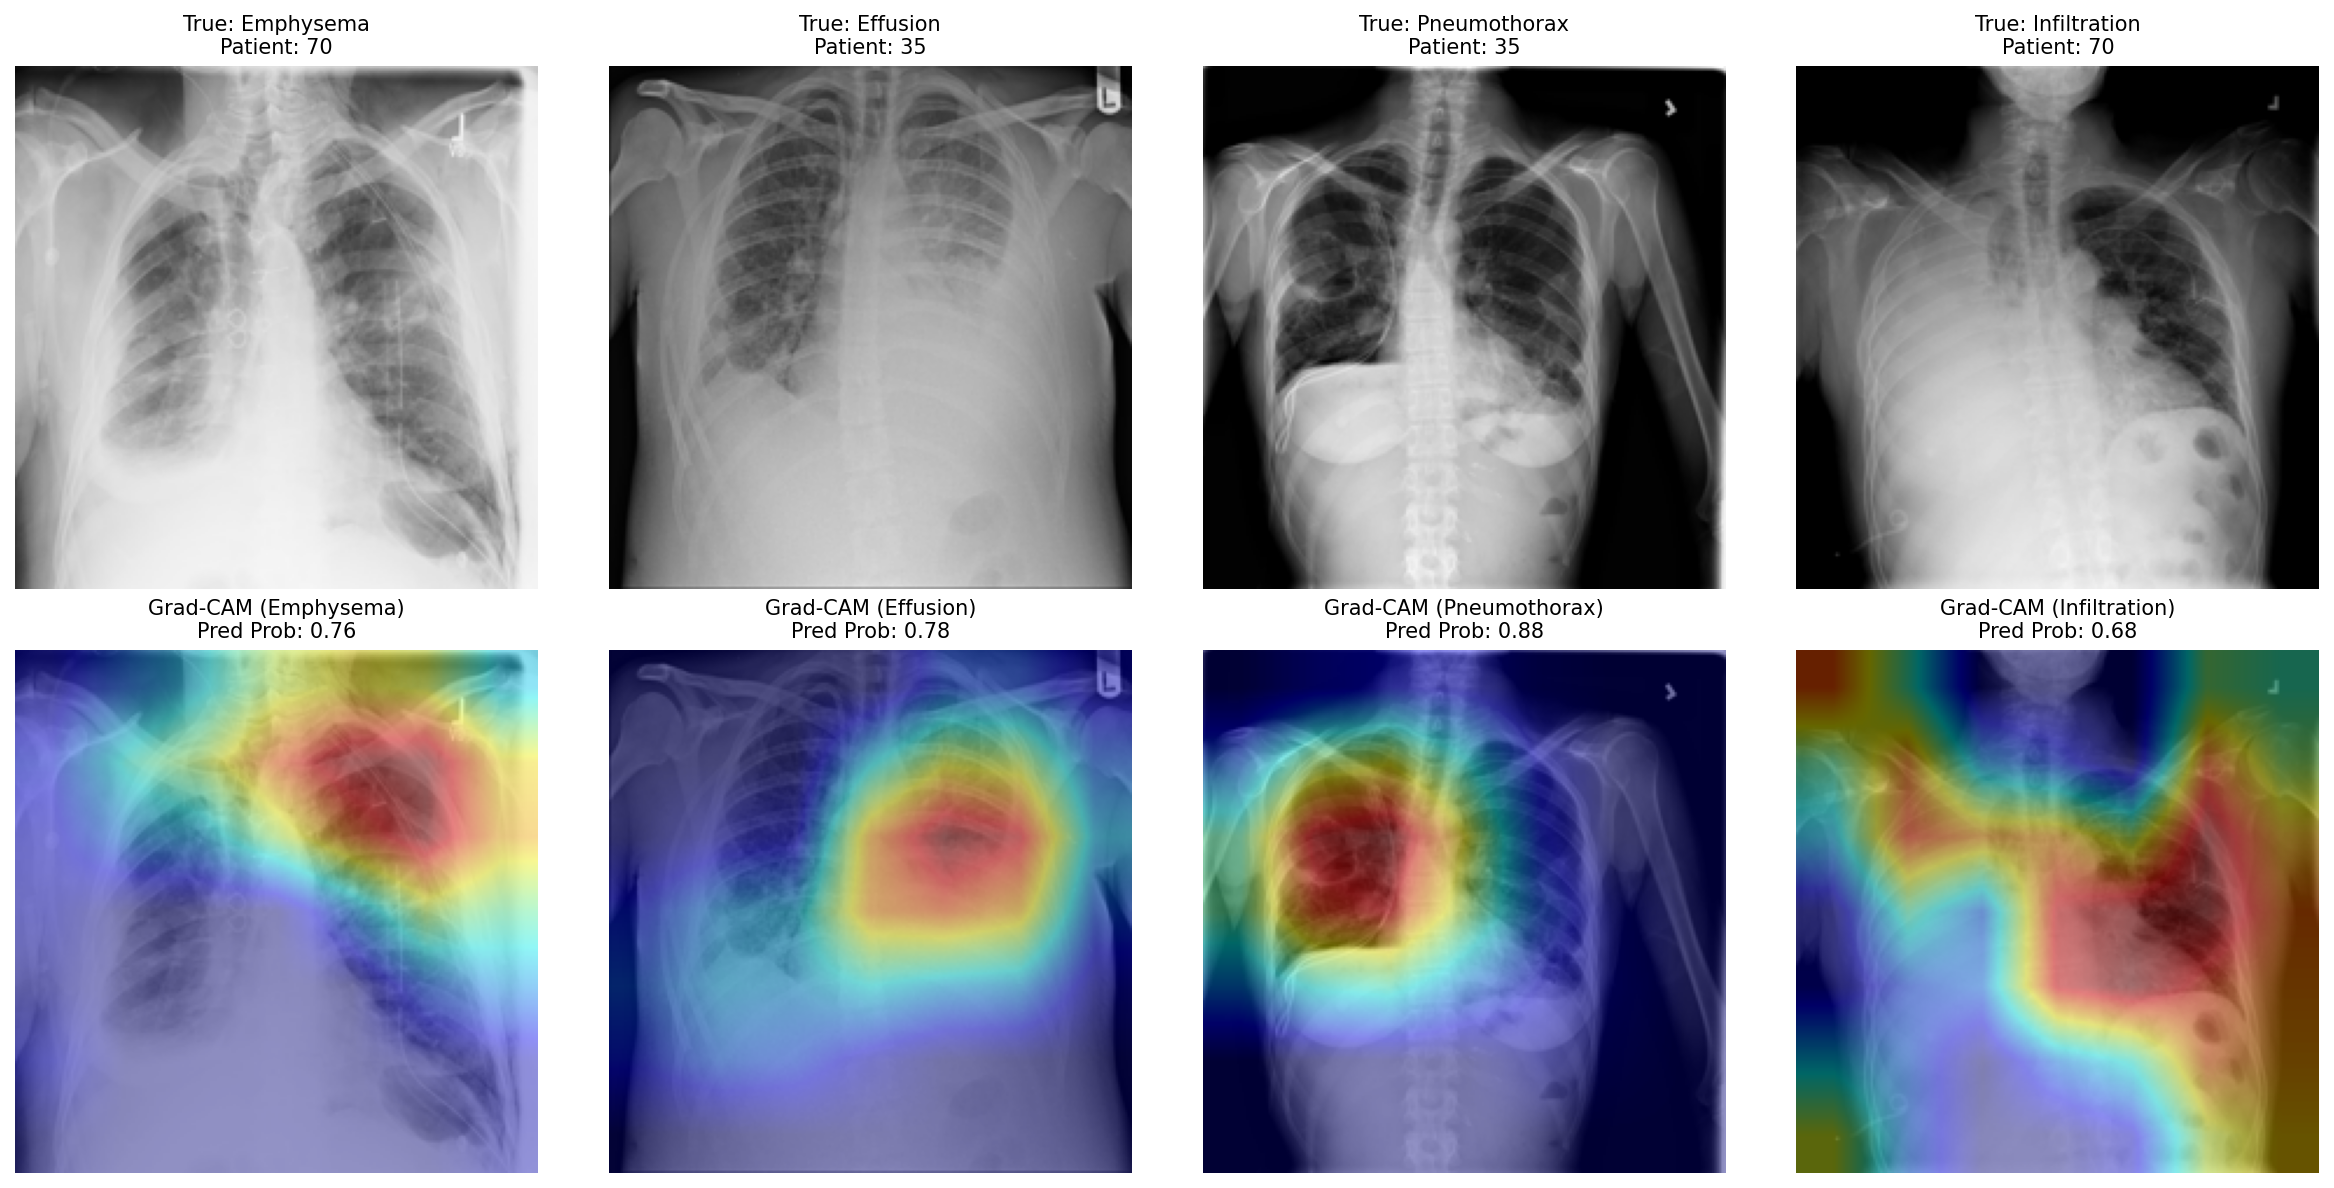

Saved Grad-CAM visualization to /content/nih_subset/gradcam_explanations.png


In [16]:
import cv2
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

class DenseNetGradCAM:
    def __init__(self, model):
        self.model = model
        self.model.eval()
        self.activations = None
        self.gradients = None

    def _save_gradient(self, grad):
        self.gradients = grad.detach()

    def generate(self, input_tensor, class_idx):
        self.model.zero_grad()

        # Pass through DenseNet feature extractor directly
        features = self.model.features(input_tensor)
        out = F.relu(features, inplace=False)  # Non-inplace ReLU avoids autograd hook conflict

        # Save activation and attach gradient hook directly to the tensor
        self.activations = out.detach()
        out.register_hook(self._save_gradient)

        # Global average pool + classifier head (matching DenseNet121 forward pass)
        pooled = F.adaptive_avg_pool2d(out, (1, 1))
        flat = torch.flatten(pooled, 1)
        logits = self.model.classifier(flat)

        prob = torch.sigmoid(logits[0, class_idx]).item()
        logits[0, class_idx].backward()

        # Compute Grad-CAM weights and spatial heatmap
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1).squeeze(0)
        cam = F.relu(cam).cpu().numpy()

        if cam.max() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min())
        cam_resized = cv2.resize(cam, (224, 224))
        return cam_resized, prob

gradcam = DenseNetGradCAM(model)

# Pick up to 4 high-confidence true-positive test cases across distinct pathologies
test_df = pd.read_csv("/content/nih_subset/test.csv")
selected_samples = []
seen_classes = set()

for idx in range(len(test_df)):
    for c_idx, p_name in enumerate(PATHOLOGIES):
        if p_name not in seen_classes and test_targets[idx, c_idx] == 1 and test_probs[idx, c_idx] > 0.65:
            selected_samples.append((idx, c_idx, p_name))
            seen_classes.add(p_name)
            break
    if len(selected_samples) == 4:
        break

if len(selected_samples) < 4:
    for idx in range(len(test_df)):
        pos_classes = np.where(test_targets[idx] == 1)[0]
        if len(pos_classes) > 0:
            c_idx = int(pos_classes[0])
            if (idx, c_idx, PATHOLOGIES[c_idx]) not in selected_samples:
                selected_samples.append((idx, c_idx, PATHOLOGIES[c_idx]))
        if len(selected_samples) == 4:
            break

# Visualize Original X-Ray vs Grad-CAM Overlay
fig, axes = plt.subplots(2, 4, figsize=(16, 8), dpi=150)

for col, (row_idx, class_idx, pathology_name) in enumerate(selected_samples):
    img_path = test_df.loc[row_idx, "image_path"]
    raw_img = np.array(Image.open(img_path).convert("RGB"))
    input_tensor = eval_transforms(Image.fromarray(raw_img)).unsqueeze(0).to(device)

    heatmap, pred_prob = gradcam.generate(input_tensor, class_idx)
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(0.60 * raw_img + 0.40 * heatmap_color)

    axes[0, col].imshow(raw_img, cmap="gray")
    axes[0, col].set_title(f"True: {pathology_name}\nPatient: {test_df.loc[row_idx, 'patient_id']}", fontsize=10)
    axes[0, col].axis("off")

    axes[1, col].imshow(overlay)
    axes[1, col].set_title(f"Grad-CAM ({pathology_name})\nPred Prob: {pred_prob:.2f}", fontsize=10)
    axes[1, col].axis("off")

plt.tight_layout()
plt.savefig("/content/nih_subset/gradcam_explanations.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved Grad-CAM visualization to /content/nih_subset/gradcam_explanations.png")

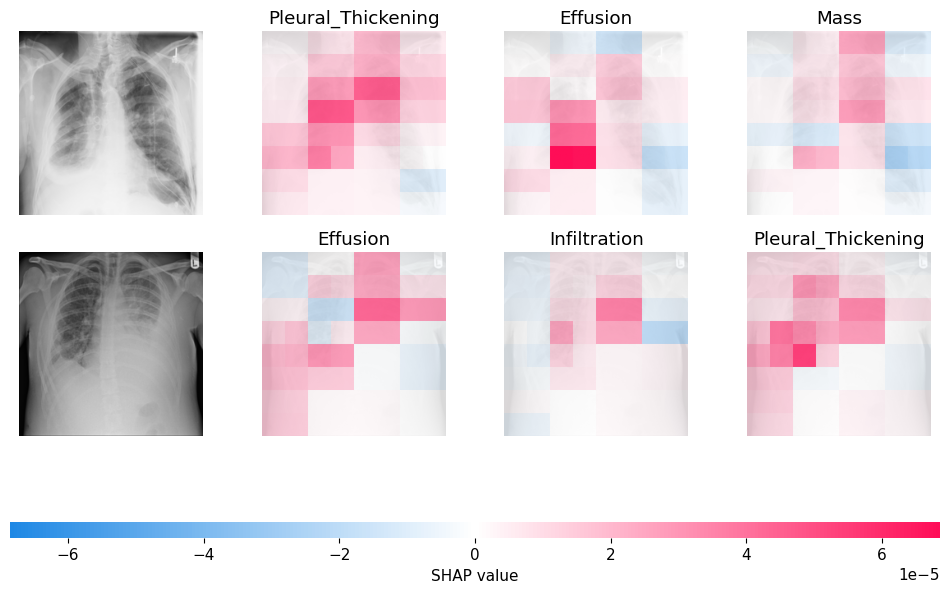

Saved SHAP pixel attribution plot to /content/nih_subset/shap_explanations.png


In [17]:
!pip install -q shap

import shap
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Wrapper function taking a batch of [N, H, W, C] uint8/float images in [0, 255]
# and returning [N, 14] sigmoid probabilities
def predict_proba_shap(images_np):
    model.eval()
    tensors = []
    for img in images_np:
        pil_img = Image.fromarray(np.uint8(img))
        tensors.append(eval_transforms(pil_img))
    batch = torch.stack(tensors).to(device)
    with torch.no_grad():
        probs = torch.sigmoid(model(batch)).cpu().numpy()
    return probs

# Use 2 true-positive test samples from our Grad-CAM selection
shap_indices = selected_samples[:2]
test_images_raw = np.array([
    np.array(Image.open(test_df.loc[row_idx, "image_path"]).convert("RGB"))
    for row_idx, _, _ in shap_indices
])

# Build an image masker using Gaussian blur over anatomical regions
masker = shap.maskers.Image("blur(32,32)", test_images_raw[0].shape)

# Initialize PartitionExplainer with the 14 pathology names
explainer = shap.Explainer(predict_proba_shap, masker, output_names=PATHOLOGIES)

# Compute Shapley attributions for the top predicted classes (max_evals=300 keeps runtime ~15s)
shap_values = explainer(
    test_images_raw,
    max_evals=300,
    batch_size=32,
    outputs=shap.Explanation.argsort.flip[:3]
)

# Plot and save SHAP attribution figure
shap.image_plot(shap_values, show=False)
plt.savefig("/content/nih_subset/shap_explanations.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved SHAP pixel attribution plot to /content/nih_subset/shap_explanations.png")

Total False-Positive predictions across test set: 1956

False-Positive count by pathology:
false_positive_class
Mass                  258
Pneumonia             232
Nodule                230
Pleural_Thickening    175
Infiltration          139
Edema                 134
Consolidation         132
Fibrosis              111
Cardiomegaly          105
Hernia                102
Emphysema             102
Atelectasis           101
Effusion               87
Pneumothorax           48
Name: count, dtype: int64

Top 8 highest-confidence False Positives:
 patient_id                                             true_labels false_positive_class  pred_prob  threshold
         80                                   Cardiomegaly|Effusion               Hernia     0.9962      0.201
         70                                                Fibrosis               Hernia     0.9880      0.201
         69                                               Emphysema               Hernia     0.9453      0.201
         70

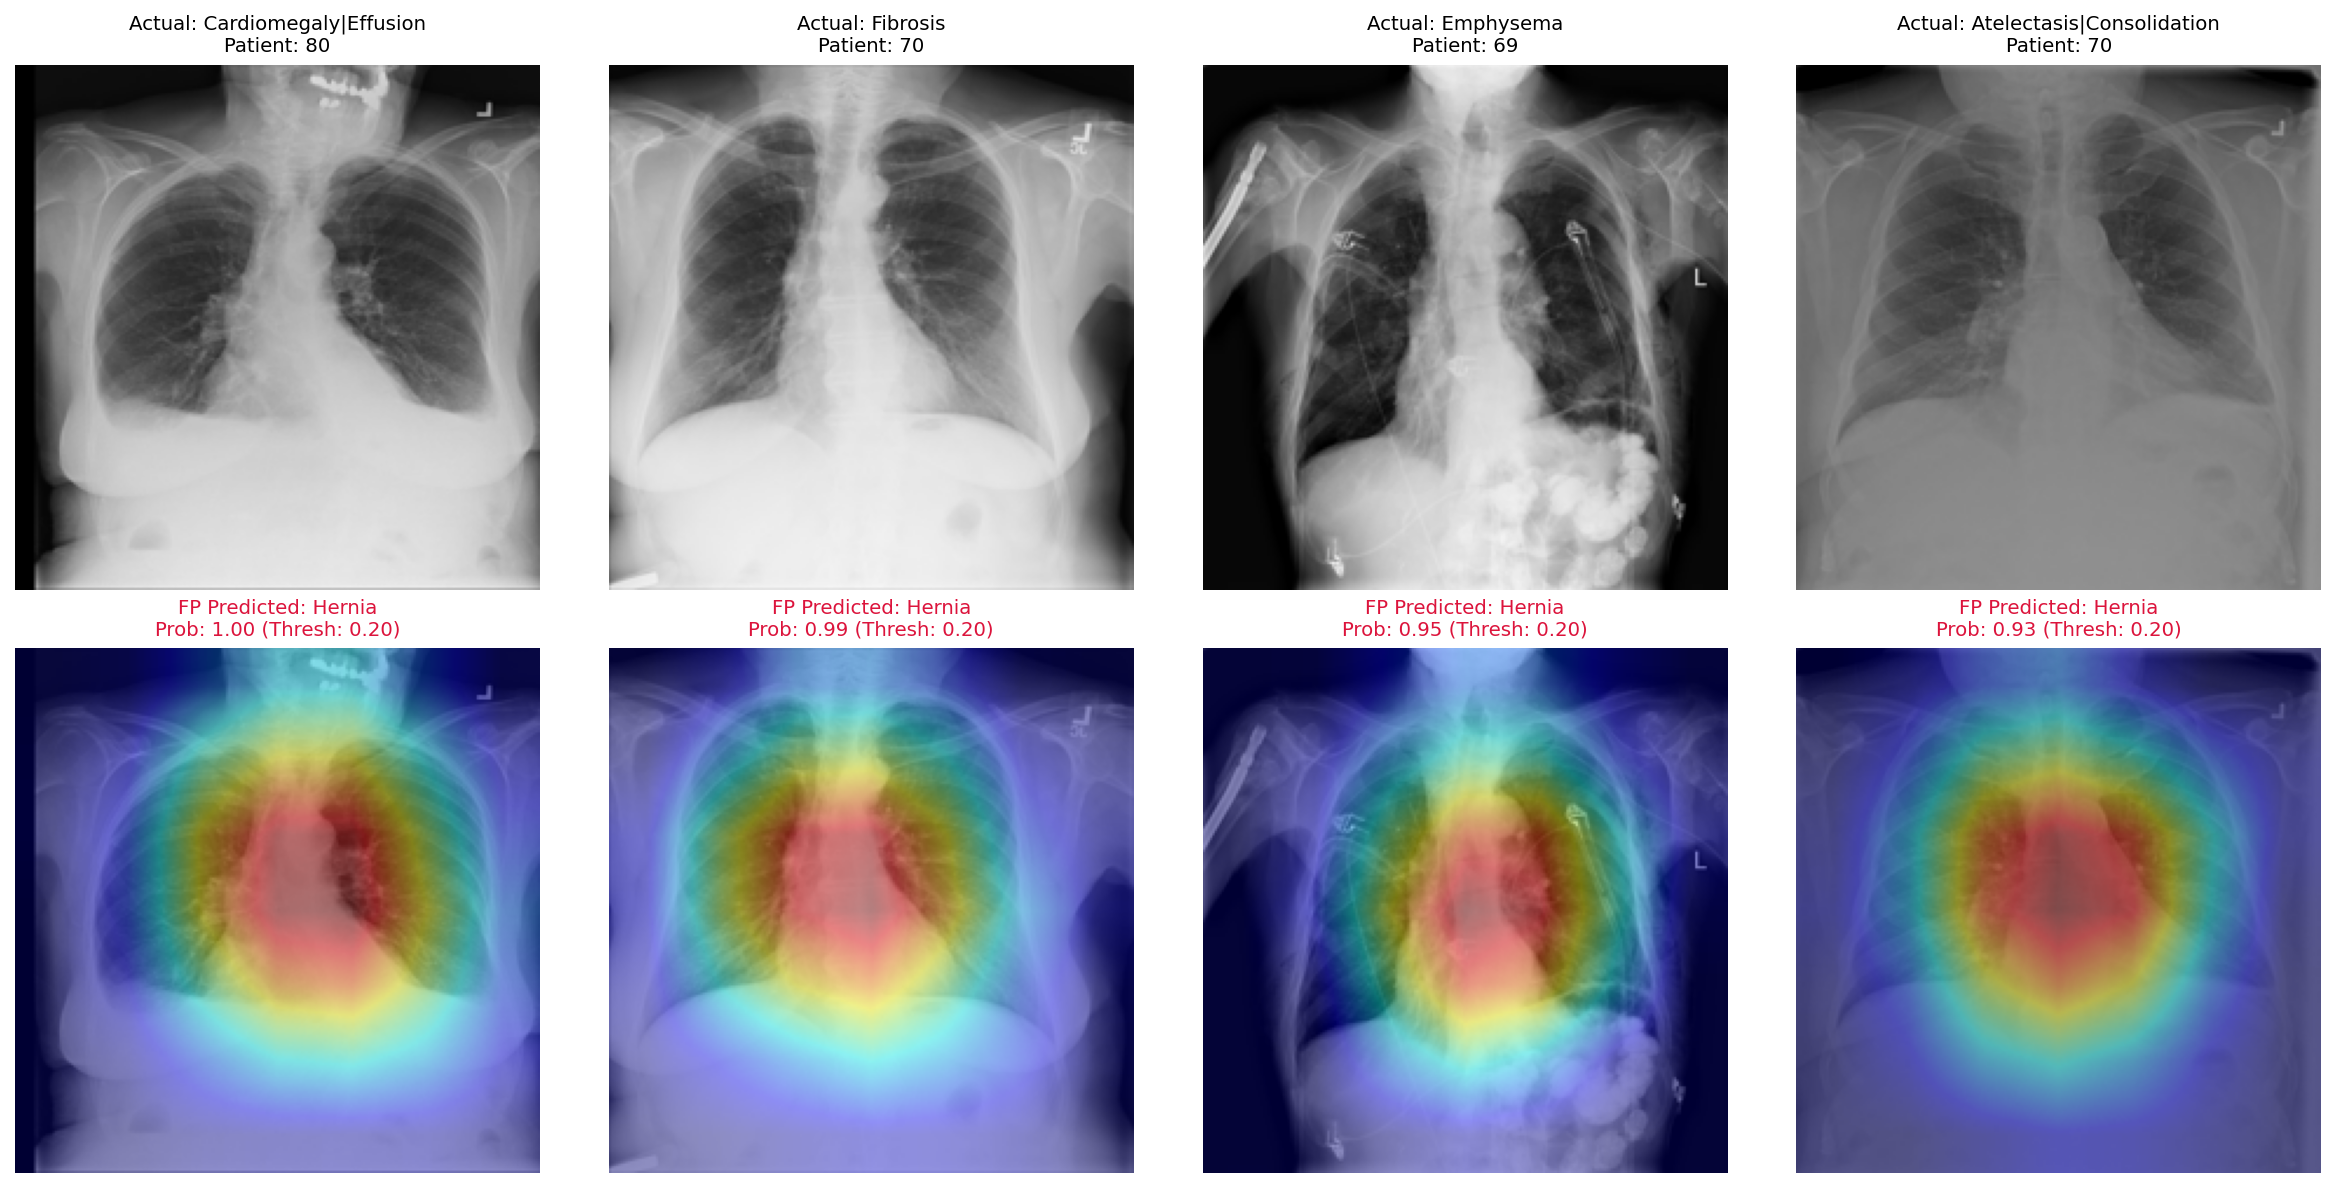

Saved false-positive Grad-CAM audit to /content/nih_subset/false_positive_gradcam.png


In [18]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Collect all false-positive predictions (ground truth == 0, predicted == 1)
fp_records = []
for row_idx in range(len(test_df)):
    for c_idx, pathology in enumerate(PATHOLOGIES):
        y_true = test_targets[row_idx, c_idx]
        y_prob = test_probs[row_idx, c_idx]
        thresh = optimal_thresholds[c_idx]

        if y_true == 0 and y_prob >= thresh:
            fp_records.append({
                "row_idx": row_idx,
                "patient_id": test_df.loc[row_idx, "patient_id"],
                "true_labels": test_df.loc[row_idx, "raw_labels"],
                "false_positive_class": pathology,
                "class_idx": c_idx,
                "pred_prob": round(float(y_prob), 4),
                "threshold": round(float(thresh), 4),
                "margin_above_thresh": round(float(y_prob - thresh), 4)
            })

fp_df = pd.DataFrame(fp_records).sort_values(by="margin_above_thresh", ascending=False).reset_index(drop=True)
fp_df.to_csv("/content/nih_subset/false_positives_audit.csv", index=False)

print(f"Total False-Positive predictions across test set: {len(fp_df)}")
print("\nFalse-Positive count by pathology:")
print(fp_df["false_positive_class"].value_counts())

print("\nTop 8 highest-confidence False Positives:")
print(fp_df[["patient_id", "true_labels", "false_positive_class", "pred_prob", "threshold"]].head(8).to_string(index=False))

# Visualize top 4 highest-confidence False Positives with Grad-CAM to inspect visual triggers
top_fps = fp_df.head(4)
fig, axes = plt.subplots(2, len(top_fps), figsize=(16, 8), dpi=150)

for col, row in top_fps.iterrows():
    r_idx = int(row["row_idx"])
    c_idx = int(row["class_idx"])
    fp_name = row["false_positive_class"]

    img_path = test_df.loc[r_idx, "image_path"]
    raw_img = np.array(Image.open(img_path).convert("RGB"))
    input_tensor = eval_transforms(Image.fromarray(raw_img)).unsqueeze(0).to(device)

    heatmap, pred_prob = gradcam.generate(input_tensor, c_idx)
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(0.60 * raw_img + 0.40 * heatmap_color)

    axes[0, col].imshow(raw_img, cmap="gray")
    axes[0, col].set_title(f"Actual: {row['true_labels']}\nPatient: {row['patient_id']}", fontsize=9.5)
    axes[0, col].axis("off")

    axes[1, col].imshow(overlay)
    axes[1, col].set_title(f"FP Predicted: {fp_name}\nProb: {pred_prob:.2f} (Thresh: {row['threshold']:.2f})", fontsize=9.5, color="crimson")
    axes[1, col].axis("off")

plt.tight_layout()
plt.savefig("/content/nih_subset/false_positive_gradcam.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved false-positive Grad-CAM audit to /content/nih_subset/false_positive_gradcam.png")

=== PUBLISHED BASELINE COMPARISON (ROC-AUC) ===
         Pathology  Test_Positives  Ours_DenseNet121_Subset  Wang_2017_AUC  CheXNet_2017_AUC  Delta_vs_Wang2017  Delta_vs_CheXNet
       Atelectasis              75                   0.6635          0.716             0.809            -0.0525           -0.1455
      Cardiomegaly              37                   0.8293          0.807             0.925             0.0223           -0.0957
     Consolidation              42                   0.6529          0.708             0.790            -0.0551           -0.1371
             Edema              41                   0.8615          0.835             0.888             0.0265           -0.0265
          Effusion              93                   0.7924          0.784             0.864             0.0084           -0.0716
         Emphysema              36                   0.8165          0.815             0.937             0.0015           -0.1205
          Fibrosis              26        

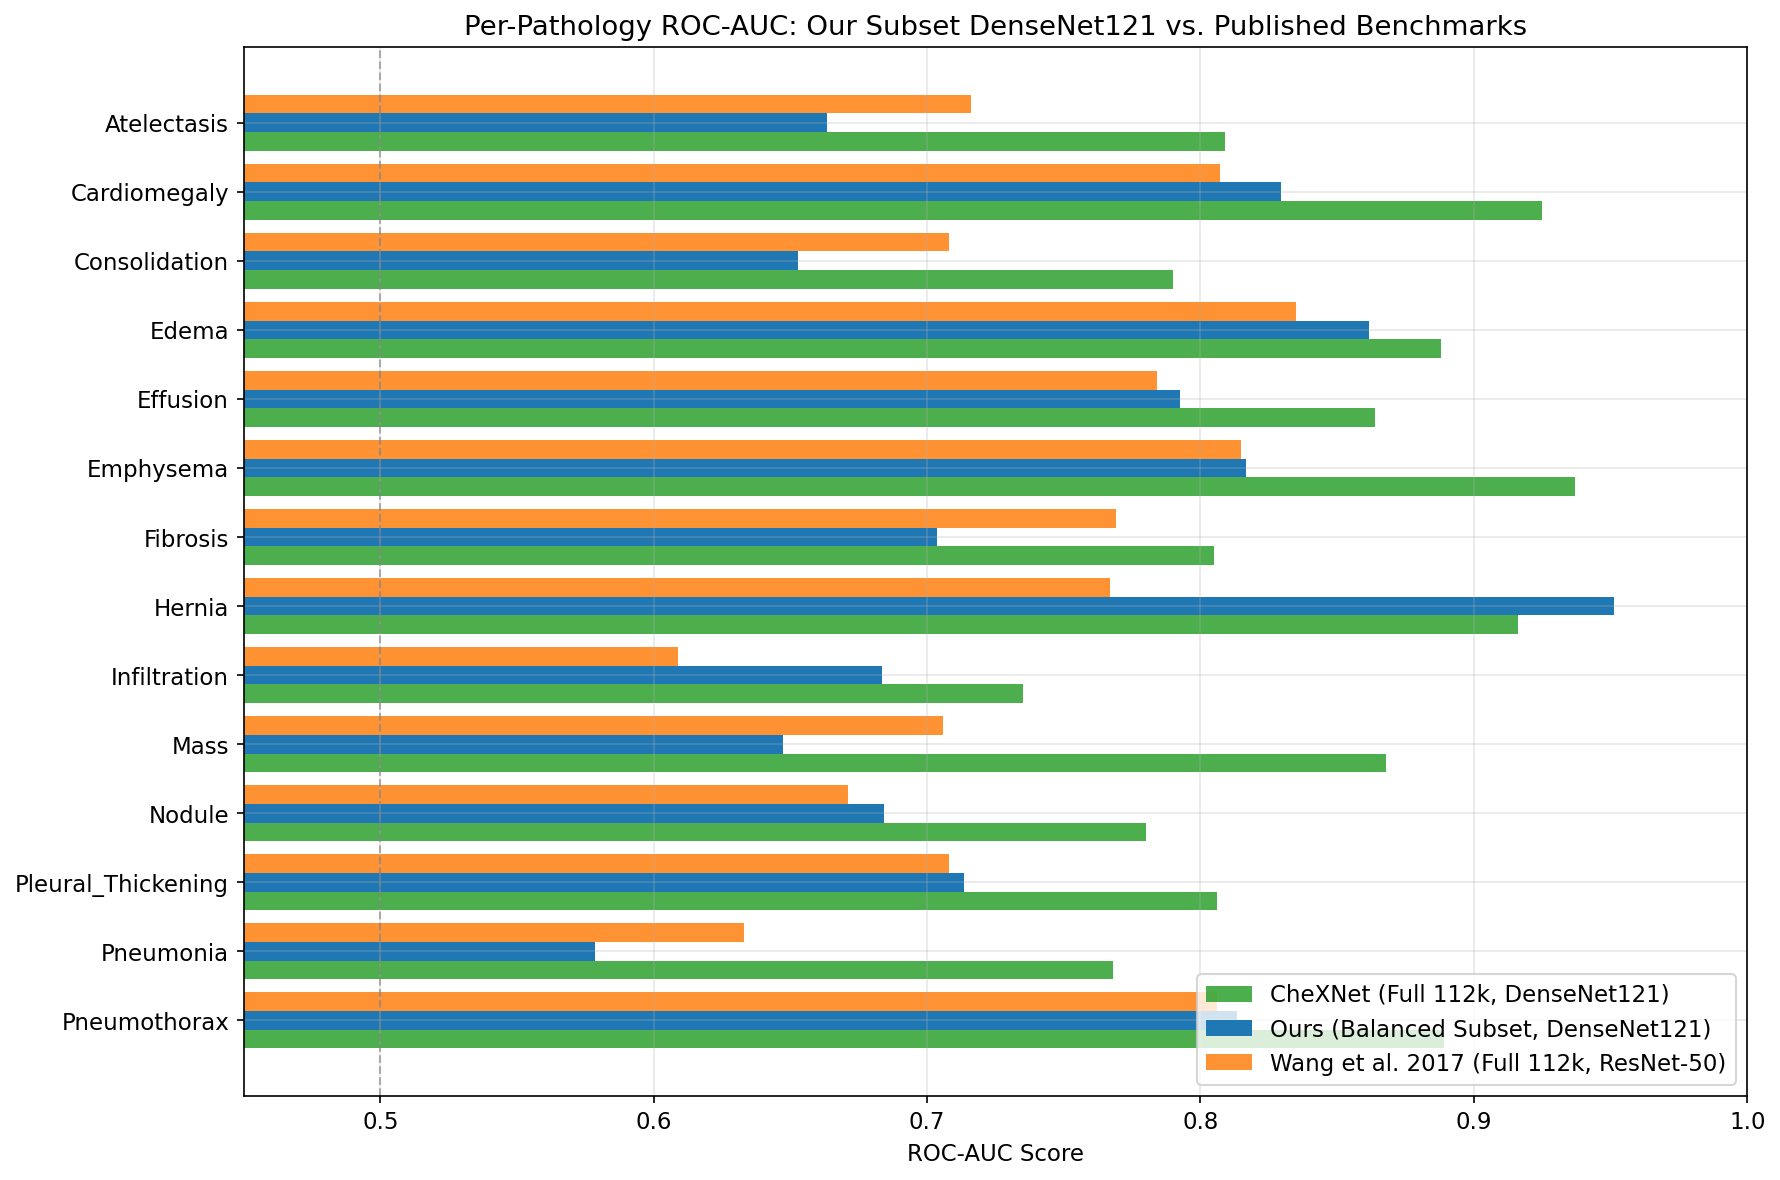

Saved baseline comparison figure to /content/nih_subset/baseline_comparison_chart.png


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your test set evaluation metrics
results_df = pd.read_csv("/content/nih_subset/test_metrics.csv")

# Published benchmark ROC-AUC scores on NIH ChestX-ray14
# 1. Wang et al. (CVPR 2017) - Original NIH ChestX-ray14 ResNet-50 baseline
# 2. Rajpurkar et al. (2017) - CheXNet (DenseNet121 trained on full 112,120 images)
published_baselines = {
    "Atelectasis":        {"Wang_2017_AUC": 0.716, "CheXNet_2017_AUC": 0.809},
    "Cardiomegaly":       {"Wang_2017_AUC": 0.807, "CheXNet_2017_AUC": 0.925},
    "Consolidation":      {"Wang_2017_AUC": 0.708, "CheXNet_2017_AUC": 0.790},
    "Edema":              {"Wang_2017_AUC": 0.835, "CheXNet_2017_AUC": 0.888},
    "Effusion":           {"Wang_2017_AUC": 0.784, "CheXNet_2017_AUC": 0.864},
    "Emphysema":          {"Wang_2017_AUC": 0.815, "CheXNet_2017_AUC": 0.937},
    "Fibrosis":           {"Wang_2017_AUC": 0.769, "CheXNet_2017_AUC": 0.805},
    "Hernia":             {"Wang_2017_AUC": 0.767, "CheXNet_2017_AUC": 0.916},
    "Infiltration":       {"Wang_2017_AUC": 0.609, "CheXNet_2017_AUC": 0.735},
    "Mass":               {"Wang_2017_AUC": 0.706, "CheXNet_2017_AUC": 0.868},
    "Nodule":             {"Wang_2017_AUC": 0.671, "CheXNet_2017_AUC": 0.780},
    "Pleural_Thickening": {"Wang_2017_AUC": 0.708, "CheXNet_2017_AUC": 0.806},
    "Pneumonia":          {"Wang_2017_AUC": 0.633, "CheXNet_2017_AUC": 0.768},
    "Pneumothorax":       {"Wang_2017_AUC": 0.806, "CheXNet_2017_AUC": 0.889},
}

baseline_df = pd.DataFrame.from_dict(published_baselines, orient="index").reset_index()
baseline_df.rename(columns={"index": "Pathology"}, inplace=True)

comp_df = pd.merge(results_df[["Pathology", "Test_Positives", "AUC"]], baseline_df, on="Pathology")
comp_df.rename(columns={"AUC": "Ours_DenseNet121_Subset"}, inplace=True)
comp_df["Delta_vs_Wang2017"] = (comp_df["Ours_DenseNet121_Subset"] - comp_df["Wang_2017_AUC"]).round(4)
comp_df["Delta_vs_CheXNet"]  = (comp_df["Ours_DenseNet121_Subset"] - comp_df["CheXNet_2017_AUC"]).round(4)

comp_df.to_csv("/content/nih_subset/literature_comparison.csv", index=False)

print("=== PUBLISHED BASELINE COMPARISON (ROC-AUC) ===")
print(comp_df.to_string(index=False))

print("\n--- Macro Mean ROC-AUC Comparison ---")
print(f"Wang et al. (2017) [Full 112k, ResNet-50]   : {comp_df['Wang_2017_AUC'].mean():.4f}")
print(f"Ours (Balanced ~3k Subset, DenseNet121)     : {comp_df['Ours_DenseNet121_Subset'].mean():.4f}")
print(f"CheXNet (2017) [Full 112k, DenseNet121]     : {comp_df['CheXNet_2017_AUC'].mean():.4f}")

# Grouped horizontal bar chart comparing all three models across the 14 pathologies
y = np.arange(len(comp_df))
height = 0.27

fig, ax = plt.subplots(figsize=(12, 8), dpi=150)
ax.barh(y + height, comp_df["CheXNet_2017_AUC"],        height, label="CheXNet (Full 112k, DenseNet121)", color="#2ca02c", alpha=0.85)
ax.barh(y,          comp_df["Ours_DenseNet121_Subset"], height, label="Ours (Balanced Subset, DenseNet121)", color="#1f77b4")
ax.barh(y - height, comp_df["Wang_2017_AUC"],           height, label="Wang et al. 2017 (Full 112k, ResNet-50)", color="#ff7f0e", alpha=0.85)

ax.set_yticks(y)
ax.set_yticklabels(comp_df["Pathology"])
ax.invert_yaxis()
ax.set_xlim(0.45, 1.0)
ax.axvline(0.5, color="gray", linestyle="--", lw=1, alpha=0.6)
ax.set_xlabel("ROC-AUC Score")
ax.set_title("Per-Pathology ROC-AUC: Our Subset DenseNet121 vs. Published Benchmarks")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("/content/nih_subset/baseline_comparison_chart.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved baseline comparison figure to /content/nih_subset/baseline_comparison_chart.png")

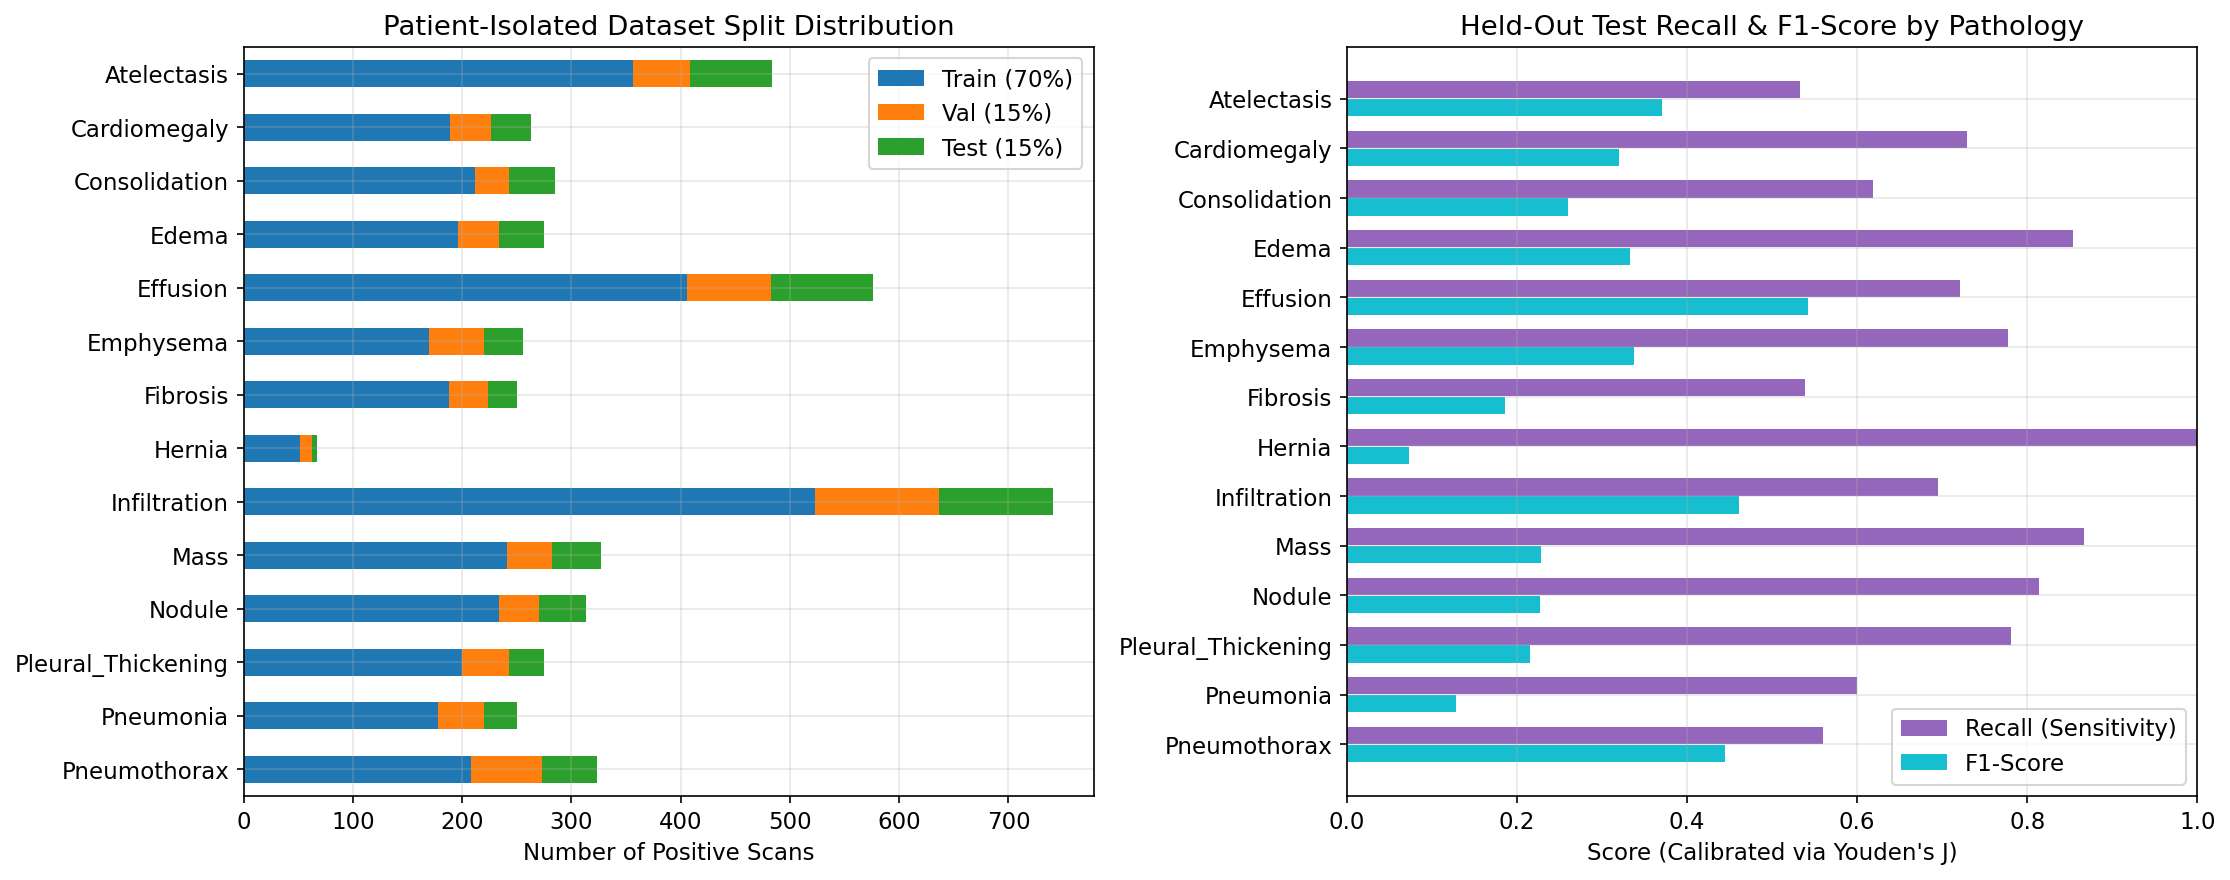

   CHEST X-RAY PATHOLOGY DETECTION WITH XAI — FINAL SUMMARY
Total Subset Scans       : 3065
Unique Patients          : 92 (Zero Cross-Split Overlap)
Split Breakdown          : Train=2177 | Val=454 | Test=434
Backbone & Loss          : DenseNet121 (ImageNet) + Class-Weighted BCEWithLogitsLoss
Best Val Mean ROC-AUC    : 0.7416
Held-Out Test Mean AUC   : 0.7423 (Wang et al. 2017: 0.7381 | CheXNet: 0.8414)
Held-Out Test Mean F1    : 0.2947
Held-Out Test Mean Recall: 0.7207
Top-Performing Pathology : Hernia (AUC = 0.9512)

Packaged all results into /content/Chest_XRay_XAI_Results.zip (28.3 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 1. Load saved split and metric tables
train_df   = pd.read_csv("/content/nih_subset/train.csv")
val_df     = pd.read_csv("/content/nih_subset/val.csv")
test_df    = pd.read_csv("/content/nih_subset/test.csv")
metrics_df = pd.read_csv("/content/nih_subset/test_metrics.csv")
comp_df    = pd.read_csv("/content/nih_subset/literature_comparison.csv")

# 2. Plot Patient-Isolated Split Distribution & Optimal Thresholds Summary
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# Panel A: Stacked bar chart of pathology counts across Train / Val / Test
split_counts = pd.DataFrame({
    "Train (70%)": train_df[PATHOLOGIES].sum(),
    "Val (15%)":   val_df[PATHOLOGIES].sum(),
    "Test (15%)":  test_df[PATHOLOGIES].sum()
})
split_counts.plot(kind="barh", stacked=True, ax=axes[0], color=["#1f77b4", "#ff7f0e", "#2ca02c"])
axes[0].invert_yaxis()
axes[0].set_xlabel("Number of Positive Scans")
axes[0].set_title("Patient-Isolated Dataset Split Distribution")
axes[0].grid(axis="x", alpha=0.3)

# Panel B: Per-Class Test F1-Score vs Recall
y = range(len(metrics_df))
axes[1].barh([i - 0.18 for i in y], metrics_df["Recall"], height=0.35, label="Recall (Sensitivity)", color="#9467bd")
axes[1].barh([i + 0.18 for i in y], metrics_df["F1"],     height=0.35, label="F1-Score",             color="#17becf")
axes[1].set_yticks(list(y))
axes[1].set_yticklabels(metrics_df["Pathology"])
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1.0)
axes[1].set_xlabel("Score (Calibrated via Youden's J)")
axes[1].set_title("Held-Out Test Recall & F1-Score by Pathology")
axes[1].legend(loc="lower right")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("/content/nih_subset/dataset_and_f1_summary.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Print Complete Project Executive Summary for Report / PPT
print("=" * 62)
print("   CHEST X-RAY PATHOLOGY DETECTION WITH XAI — FINAL SUMMARY")
print("=" * 62)
print(f"Total Subset Scans       : {len(train_df) + len(val_df) + len(test_df)}")
print(f"Unique Patients          : {train_df['patient_id'].nunique() + val_df['patient_id'].nunique() + test_df['patient_id'].nunique()} (Zero Cross-Split Overlap)")
print(f"Split Breakdown          : Train={len(train_df)} | Val={len(val_df)} | Test={len(test_df)}")
print(f"Backbone & Loss          : DenseNet121 (ImageNet) + Class-Weighted BCEWithLogitsLoss")
print(f"Best Val Mean ROC-AUC    : {best_val_auc:.4f}")
print(f"Held-Out Test Mean AUC   : {metrics_df['AUC'].mean():.4f} (Wang et al. 2017: {comp_df['Wang_2017_AUC'].mean():.4f} | CheXNet: {comp_df['CheXNet_2017_AUC'].mean():.4f})")
print(f"Held-Out Test Mean F1    : {metrics_df['F1'].mean():.4f}")
print(f"Held-Out Test Mean Recall: {metrics_df['Recall'].mean():.4f}")
print(f"Top-Performing Pathology : {metrics_df.sort_values('AUC', ascending=False).iloc[0]['Pathology']} (AUC = {metrics_df['AUC'].max():.4f})")
print("=" * 62)

# 4. Bundle all figures, CSVs, and model weights into one ZIP archive
zip_path = "/content/Chest_XRay_XAI_Results.zip"
files_to_bundle = [
    "/content/nih_subset/best_densenet121.pth",
    "/content/nih_subset/train.csv",
    "/content/nih_subset/val.csv",
    "/content/nih_subset/test.csv",
    "/content/nih_subset/test_metrics.csv",
    "/content/nih_subset/false_positives_audit.csv",
    "/content/nih_subset/literature_comparison.csv",
    "/content/nih_subset/roc_and_training_curves.png",
    "/content/nih_subset/gradcam_explanations.png",
    "/content/nih_subset/shap_explanations.png",
    "/content/nih_subset/false_positive_gradcam.png",
    "/content/nih_subset/baseline_comparison_chart.png",
    "/content/nih_subset/dataset_and_f1_summary.png",
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for fpath in files_to_bundle:
        if os.path.exists(fpath):
            zf.write(fpath, arcname=os.path.basename(fpath))

print(f"\nPackaged all results into {zip_path} ({os.path.getsize(zip_path) / (1024*1024):.1f} MB)")
files.download(zip_path)